# Коллаборативная фильтрация: соседи пользователей и товаров

## Введение

Поведенческое сходство связывает людей с похожими историями или товары, встречавшиеся у одних людей. Оно обнаруживает совместный интерес даже между разными категориями. В отличие от сходства карточек, здесь сигнал создают действия аудитории.

Практика использует 300 известных пользователей и 180 товаров. События синтетические; исходные названия, цены и категории взяты из каталога. Сходство строится по факту взаимодействия, а оценка кандидата учитывает силу действий. Апрель служит для настройки, май — для итоговой проверки. Кандидатами остаётся весь каталог; уже встречавшиеся предметы скрываются. Отсутствие события не считается отрицательным отзывом.

Будут построены две модели соседства, проверены источники отдельных оценок, выбраны число соседей и сглаживание. Затем модели с фиксированными настройками переобучаются на истории до мая и проверяются на майских новых покупках.

## Матрицы и временная граница

В разреженной таблице строки обозначают пользователей, столбцы — товары. Матрица B содержит только факт взаимодействия и нужна для поиска соседей. Матрица R содержит log1p суммы сил просмотров, добавлений в корзину и покупок; она передаёт вес кандидату. Логарифм сдерживает повторные действия. Числовой идентификатор человека адресует строку и не является признаком вкуса.

Начальная ячейка задаёт библиотеки и находит папку модуля. Разреженные матрицы позволяют хранить известные взаимодействия без плотной таблицы всех возможных пар. Импорты далее не повторяются. Напечатанное имя каталога помогает проверить, к каким локальным данным привязаны вычисления.

In [1]:
# Шаг М4.03.01 — Импорты и каталог
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
module_name = "Модуль 4 Рекомендательные системы"
candidates = [candidate for root in [Path.cwd(), *Path.cwd().parents]
              for candidate in (root, root / "course" / "practice" / module_name)]
MODULE_DIR = next(p for p in candidates if p.name == module_name and p.is_dir())
DATA_DIR = MODULE_DIR / "data"
SOURCE_DIR = MODULE_DIR.parent.parent / "data"
print("Каталог материалов:", MODULE_DIR.name)

Каталог материалов: Модуль 4 Рекомендательные системы


Функции удаляют повторные event_id, отделяют историю от будущих покупок, строят B и R, скрывают ранее виденное и ранжируют все товары каталога. Для настройки история заканчивается до апреля, а цели — новые покупки апреля. Для итоговой проверки история заканчивается до мая, а цели — новые покупки мая.

In [2]:
# Шаг М4.03.02 — Единый протокол оценки
def load_context(phase="validation"):
    if phase not in {"validation", "test"}:
        raise ValueError("Ожидается validation или test")
    catalog = pd.read_csv(DATA_DIR / "reco_catalog.csv").sort_values("product_id").reset_index(drop=True)
    events = pd.read_csv(DATA_DIR / "reco_events.csv", parse_dates=["timestamp"]).drop_duplicates("event_id")
    cut = pd.Timestamp("2025-04-01" if phase == "validation" else "2025-05-01")
    end = pd.Timestamp("2025-05-01" if phase == "validation" else "2025-06-01")
    history = events[events.timestamp < cut].copy()
    future = events[(events.timestamp >= cut) & (events.timestamp < end) & (events.event_type == "purchase")]
    user_ids = np.arange(1, 301)  # Известный учебный реестр, а не признак предпочтения.
    item_ids = catalog.product_id.to_numpy()
    u_map = {int(value): index for index, value in enumerate(user_ids)}
    i_map = {int(value): index for index, value in enumerate(item_ids)}
    history["strength"] = history.event_type.map({"view": 1.0, "cart": 3.0, "purchase": 5.0})
    pairs = history.groupby(["user_id", "product_id"]).strength.sum().reset_index()
    R = sparse.csr_matrix((np.log1p(pairs.strength),
                           (pairs.user_id.map(u_map), pairs.product_id.map(i_map))),
                          shape=(len(user_ids), len(item_ids)))
    B = R.copy()
    B.data[:] = 1.0
    seen = B.toarray().astype(bool)  # Только 300 x 180; полный большой каталог так не разворачивается.
    truth = {int(u): set(g.product_id) - set(item_ids[seen[u_map[int(u)]]])
             for u, g in future.groupby("user_id")}
    purchases = history[history.event_type.eq("purchase")].drop_duplicates(["user_id", "product_id"])
    popularity = purchases.groupby("product_id").size().reindex(item_ids, fill_value=0).to_numpy(float)
    return dict(catalog=catalog, events=events, history=history, R=R, B=B, seen=seen,
                truth=truth, user_ids=user_ids, item_ids=item_ids, u_map=u_map,
                i_map=i_map, popularity=popularity, cut=cut, end=end, phase=phase)

def top_indices(scores, seen, k=10):
    values = np.array(scores, dtype=float, copy=True)
    if values.ndim != 2 or values.shape != seen.shape or not np.isfinite(values).all():
        raise ValueError("Нужна конечная матрица оценок формы user x item")
    values[seen] = -np.inf
    result = []
    for row in values:
        order = np.argsort(-row, kind="stable")
        result.append(order[np.isfinite(row[order])][:k])
    return result

def evaluate(scores, ctx, k=10):
    ranked = top_indices(scores, ctx["seen"], k)
    rows = []
    for u, relevant in ctx["truth"].items():
        if not relevant:
            continue
        ui = ctx["u_map"][u]
        recommended = ctx["item_ids"][ranked[ui]]
        hits = np.isin(recommended, list(relevant)).astype(float)
        discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
        ideal = (1 / np.log2(np.arange(2, min(k, len(relevant)) + 2))).sum()
        positions = np.flatnonzero(hits)
        rows.append(dict(user_id=u, history_size=int(ctx["seen"][ui].sum()), n_truth=len(relevant),
                         precision=float(hits.sum()/k), recall=float(hits.sum()/len(relevant)),
                         ndcg=float(hits @ discounts / ideal), hit=float(hits.any()),
                         mrr=0.0 if not len(positions) else 1.0/(positions[0]+1)))
    return pd.DataFrame(rows)

def summarize(scores, ctx, k=10):
    detail = evaluate(scores, ctx, k)
    ranked = top_indices(scores, ctx["seen"], k)
    evaluated_rows = [ranked[ctx["u_map"][int(u)]] for u in detail.user_id]
    chosen = np.concatenate(evaluated_rows)
    novelty = -np.log2((ctx["popularity"]+1)/(ctx["popularity"].sum()+len(ctx["item_ids"])))
    return pd.Series({"Precision@K":detail.precision.mean(), "Recall@K":detail.recall.mean(),
                      "NDCG@K":detail.ndcg.mean(), "HitRate@K":detail.hit.mean(),
                      "Coverage":len(np.unique(chosen))/len(ctx["item_ids"]),
                      "Novelty":float(novelty[chosen].mean()), "users":len(detail)})

def popular_scores(ctx):
    return np.tile(ctx["popularity"], (len(ctx["user_ids"]), 1))

Апрельский срез нужен только для настройки. Фактическая последняя дата истории позволяет проверить временную границу. Число людей с новыми покупками показывает объём оценочной группы и может быть меньше известного реестра из 300 строк.

In [3]:
# Шаг М4.03.03 — Апрельский контекст
val = load_context("validation")
print("Пользователи:",len(val["user_ids"]),"товары:",len(val["item_ids"]))
print("События после очистки:",len(val["events"]))
print("Граница:",val["cut"].date(),"последнее событие истории:",val["history"].timestamp.max().date())
print("Пользователей с новой покупкой:",sum(bool(x) for x in val["truth"].values()))

Пользователи: 300 товары: 180
События после очистки: 11234
Граница: 2025-04-01 последнее событие истории: 2025-03-31
Пользователей с новой покупкой: 290


Нулевые счётчики подтверждают очистку дубликатов и временное разделение. Таблица состава действий помогает понять, какие события формируют матрицы. Просмотр и покупка одинаково отмечают факт в B, но дают разные веса в R.

In [4]:
# Шаг М4.03.04 — Дубли и типы действий
print("Повторных ID после очистки:",int(val["events"].event_id.duplicated().sum()))
print("Событий за границей:",int((val["history"].timestamp>=val["cut"]).sum()))
display(val["history"].event_type.value_counts().rename_axis("событие").to_frame("число"))

Повторных ID после очистки: 0
Событий за границей: 0


,число
событие,
view,3357
purchase,1550
cart,1017


B и R имеют одинаковые размеры, но значения известной пары различаются: единица факта против логарифма накопленной силы. Плотность описывает долю наблюдённых пар. Остальные клетки не становятся отрицательными отзывами только потому, что пользователь не оставил событие.

In [5]:
# Шаг М4.03.05 — Разреженность и вес пары
B,R = val["B"],val["R"]
print("Форма:",B.shape,"ненулевых пар:",B.nnz,"доля:",round(B.nnz/(B.shape[0]*B.shape[1]),4))
sample = val["history"].groupby(["user_id","product_id"]).strength.sum().reset_index().iloc[0]
ui,ii = val["u_map"][int(sample.user_id)],val["i_map"][int(sample.product_id)]
print("B:",B[ui,ii],"R:",round(float(R[ui,ii]),4),"log1p:",round(float(np.log1p(sample.strength)),4))

Форма: (300, 180) ненулевых пар: 5040 доля: 0.0933
B: 1.0 R: 1.7918 log1p: 1.7918


Первый график показывает разницу в объёме истории. Короткая строка даёт слабую опору для поиска соседей, а пустая строка не даёт персонального сигнала. Медиана описывает типичного пользователя без чрезмерного влияния длинных историй.

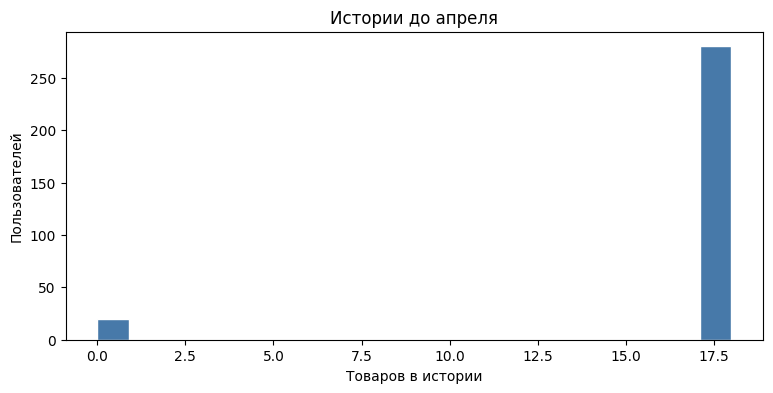

Пустых: 20 медиана: 18.0


In [6]:
# Шаг М4.03.06 — Длины историй
lengths = np.asarray(B.sum(axis=1)).ravel()
fig,ax = plt.subplots()
ax.hist(lengths,bins=20,color="#4779a9",edgecolor="white")
ax.set(xlabel="Товаров в истории",ylabel="Пользователей",title="Истории до апреля")
plt.show()
print("Пустых:",int((lengths==0).sum()),"медиана:",float(np.median(lengths)))

## Соседство товаров

Товар — это столбец B с отметками людей, взаимодействовавших с ним. Произведение B.T @ B считает совместные встречи. Косинус делит пересечение на геометрическое среднее частот двух товаров. Сглаживание ослабляет редкое пересечение. После отбора лучших соседей исторические товары передают вес кандидатам через R.

Внедиагональная клетка B.T @ B равна числу людей, встречавших оба товара. Для пары с наибольшим пересечением выводятся названия и частоты. Большое число совпадений ещё не доказывает сильную близость, поскольку популярные товары чаще пересекаются.

In [7]:
# Шаг М4.03.07 — Совместные пользователи двух товаров
item_count = np.asarray(B.sum(axis=0)).ravel()
co_item = (B.T@B).toarray()
np.fill_diagonal(co_item,0)
pair = np.unravel_index(np.argmax(co_item),co_item.shape)
print("Пересечение:",int(co_item[pair]),"частоты:",item_count[list(pair)].tolist())
display(val["catalog"].loc[list(pair),["product_id","name","category"]])

Пересечение: 34 частоты: [66.0, 62.0]


,product_id,name,category
17,18,Красота товар 18,Красота
170,285,Красота товар 285,Красота


Косинус нормирует пересечение на частоты обеих позиций. Ручной расчёт выбранной пары сверяется с матричным, чтобы обнаружить ошибку оси или знаменателя. До ограничения соседей матрица симметрична; после отбора исходящих связей это свойство не обязательно.

In [8]:
# Шаг М4.03.08 — Бинарный косинус товаров
denom = np.sqrt(np.outer(item_count,item_count))
item_cos = np.divide(co_item,denom,out=np.zeros_like(co_item,dtype=float),where=denom>0)
i,j = pair
print("Ручной:",round(float(co_item[i,j]/np.sqrt(item_count[i]*item_count[j])),4))
print("Матричный:",round(float(item_cos[i,j]),4),"симметрия:",bool(np.allclose(item_cos,item_cos.T)))

Ручной: 0.5315
Матричный: 0.5315 симметрия: True


Второй график показывает множитель co/(co+shrink). Одно совпадение при положительном сглаживании ослабляется сильнее устойчивого пересечения. Нулевое значение сохраняет исходный косинус. Параметр будет выбран по апрельской проверке, без обращения к майским покупкам.

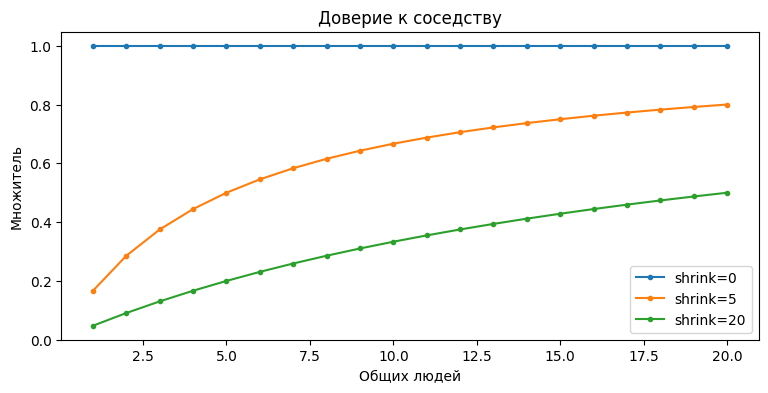

In [9]:
# Шаг М4.03.09 — Сглаживание пересечений
crossings=np.arange(1,21)
fig,ax=plt.subplots()
for sh in (0,5,20):
    ax.plot(crossings,crossings/(crossings+sh),marker="o",markersize=3,label=f"shrink={sh}")
ax.set(xlabel="Общих людей",ylabel="Множитель",title="Доверие к соседству")
ax.legend()
plt.show()

Функция оставляет заданное число сильнейших исходящих связей каждого товара и вычисляет R @ S. Элемент S[i,j] передаёт вес от исторического i к кандидату j. Для пользователя без событий оценка заменяется популярностью. Возврат матрицы связей позволяет проверить отдельную рекомендацию.

In [10]:
# Шаг М4.03.10 — Функция item-item
def item_knn_scores(ctx, neighbors=20, shrink=5.0):
    B = ctx["B"]
    counts = np.asarray(B.sum(axis=0)).ravel()
    co = (B.T @ B).toarray()
    denominator = np.sqrt(np.outer(counts, counts))
    similarity = np.divide(co, denominator, out=np.zeros_like(co), where=denominator>0)
    similarity *= np.divide(co, co + shrink, out=np.zeros_like(co, dtype=float), where=(co + shrink)>0)
    np.fill_diagonal(similarity, 0)
    selected = np.zeros_like(similarity)
    for i, row in enumerate(similarity):
        idx = np.argsort(-row, kind="stable")[:neighbors]
        selected[i, idx] = row[idx]
    scores = np.asarray(ctx["R"] @ selected)
    # S_ij задаёт переход из исторического i к кандидату j; строки обрезаны до соседей.
    cold = np.asarray(B.sum(axis=1)).ravel() == 0
    scores[cold] = ctx["popularity"]
    return scores, selected

Выводятся исходящие связи одного товара. Название и категория помогают увидеть, что аудитория может связывать разные категории. Число близости не является вероятностью покупки: оно отражает нормированное и сглаженное пересечение историй пользователей.

In [11]:
# Шаг М4.03.11 — Соседи выбранного товара
item_scores,item_links=item_knn_scores(val,neighbors=20,shrink=5)
source=int(np.argmax(item_count))
near=np.argsort(-item_links[source],kind="stable")[:6]
near=near[item_links[source,near]>0]
view=val["catalog"].loc[near,["product_id","name","category"]].copy()
view["близость"]=np.round(item_links[source,near],4)
print("Источник:",val["catalog"].loc[source,"name"])
display(view)

Источник: Красота товар 18


,product_id,name,category,близость
170,285,Красота товар 285,Красота,0.4634
137,169,Красота товар 169,Красота,0.4136
171,287,Красота товар 287,Красота,0.3927
74,75,Красота товар 75,Красота,0.3563
142,180,Красота товар 180,Красота,0.3438
156,228,Красота товар 228,Красота,0.3130


Оценка верхнего кандидата раскладывается по историческим товарам пользователя. Вклад равен силе действия, умноженной на связь с кандидатом. Сумма всех вкладов проверяет матричный результат; таблица оставляет несколько крупнейших источников для чтения.

In [12]:
# Шаг М4.03.12 — Вклад исторических товаров
u=int(val["user_ids"][np.argmax(lengths)])
ui=val["u_map"][u]
candidate=top_indices(item_scores,val["seen"],10)[ui][0]
sources=R[ui].indices
contrib=R[ui,sources].toarray().ravel()*item_links[sources,candidate]
order=np.argsort(-contrib,kind="stable")[:5]
proof=val["catalog"].loc[sources[order],["product_id","name"]].copy()
proof["вклад"]=np.round(contrib[order],4)
print("Пользователь:",u,"кандидат:",val["catalog"].loc[candidate,"name"])
display(proof)
print("Оценка:",round(float(item_scores[ui,candidate]),4),"сумма:",round(float(contrib.sum()),4))

Пользователь: 1 кандидат: Продукты товар 20


,product_id,name,вклад
51,52,Продукты товар 52,0.5137
4,5,Продукты товар 5,0.3749
67,68,Продукты товар 68,0.3654
10,11,Продукты товар 11,0.3505
62,63,Продукты товар 63,0.3505


Оценка: 2.7795 сумма: 2.7795


## Соседство пользователей

В user-user модели сравниваются строки B. Их пересечение показывает общие товары, а косинус нормирует совпадение на длины обеих историй. Сглаживание ослабляет малое число общих предметов. После отбора похожих людей их взвешенные действия из R формируют оценку кандидата. Идентификатор пользователя выбирает строку; разница числовых ID не имеет смысла.

Произведение B @ B.T имеет размер пользователь на пользователь. За пределами диагонали оно содержит число общих товаров. Выбранная пара показывает пересечение и длины историй; без нормировки длинные профили естественно получают больше совпадений.

In [13]:
# Шаг М4.03.13 — Общие товары двух людей
user_count=np.asarray(B.sum(axis=1)).ravel()
co_user=(B@B.T).toarray()
np.fill_diagonal(co_user,0)
upair=np.unravel_index(np.argmax(co_user),co_user.shape)
print("Пользователи:",val["user_ids"][list(upair)].tolist())
print("Общих товаров:",int(co_user[upair]),"длины историй:",user_count[list(upair)].tolist())

Пользователи: [10, 44]
Общих товаров: 11 длины историй: [18.0, 18.0]


Косинус строки делит число общих товаров на корень из произведения длин историй. Ручная проверка подтверждает формулу и размер пользовательской матрицы. Нулевой знаменатель безопасно даёт нулевую близость, поскольку пустая история не предоставляет оснований для сравнения.

In [14]:
# Шаг М4.03.14 — Косинус пользовательских историй
ud=np.sqrt(np.outer(user_count,user_count))
user_cos=np.divide(co_user,ud,out=np.zeros_like(co_user,dtype=float),where=ud>0)
a,b=upair
print("Ручной:",round(float(co_user[a,b]/np.sqrt(user_count[a]*user_count[b])),4))
print("Матричный:",round(float(user_cos[a,b]),4),"форма:",user_cos.shape)

Ручной: 0.6111
Матричный: 0.6111 форма: (300, 300)


Строка связей целевого пользователя указывает выбранных похожих людей. Произведение этой строки на R соседей даёт оценки товаров. Собственная диагональ исключена; пустому профилю подставляется популярность. Возвращённая матрица связей понадобится для диагностики вклада.

In [15]:
# Шаг М4.03.15 — Функция user-user
def user_knn_scores(ctx,neighbors=20,shrink=5.0):
    B=ctx["B"]
    counts=np.asarray(B.sum(axis=1)).ravel()
    co=(B@B.T).toarray()
    denom=np.sqrt(np.outer(counts,counts))
    sim=np.divide(co,denom,out=np.zeros_like(co,dtype=float),where=denom>0)
    sim*=np.divide(co,co+shrink,out=np.zeros_like(co,dtype=float),where=(co+shrink)>0)
    np.fill_diagonal(sim,0)
    selected=np.zeros_like(sim)
    for u,row in enumerate(sim):
        idx=np.argsort(-row,kind="stable")[:neighbors]
        selected[u,idx]=row[idx]
    scores=np.asarray(selected@ctx["R"])
    cold=counts==0
    scores[cold]=ctx["popularity"]
    return scores,selected

user_scores,user_links=user_knn_scores(val)
print("Оценки:",user_scores.shape,"связи:",user_links.shape)

Оценки: (300, 180) связи: (300, 300)


Для человека с богатой историей показываются ближайшие профили, их близость и размер истории. Числа user_id помогают обратиться к строкам, но расстояние между значениями идентификаторов не участвует в сходстве. Размер профиля помогает заметить хрупкую связь.

In [16]:
# Шаг М4.03.16 — Соседи одного человека
target=int(np.argmax(user_count))
near_u=np.argsort(-user_links[target],kind="stable")[:6]
near_u=near_u[user_links[target,near_u]>0]
display(pd.DataFrame({"user_id":val["user_ids"][near_u],
                      "близость":np.round(user_links[target,near_u],4),
                      "товаров_в_истории":user_count[near_u]}))
print("Целевой пользователь:",int(val["user_ids"][target]))

,user_id,близость,товаров_в_истории
0,89,0.3214,18.0
1,42,0.2735,18.0
2,132,0.2735,18.0
3,251,0.2735,18.0
4,4,0.2269,18.0
5,41,0.2269,18.0


Целевой пользователь: 1


Оценка кандидата раскладывается по похожим людям: близость соседа умножается на силу его действия с этим товаром. Полная сумма должна совпасть с общей оценкой. Здесь источник балла — люди, тогда как в item-item источником были товары истории.

In [17]:
# Шаг М4.03.17 — Вклад соседних людей
candidate_u=top_indices(user_scores,val["seen"],10)[target][0]
neighbors=np.flatnonzero(user_links[target])
weights=user_links[target,neighbors]*R[neighbors,candidate_u].toarray().ravel()
order=np.argsort(-weights,kind="stable")[:5]
display(pd.DataFrame({"user_id":val["user_ids"][neighbors[order]],"вклад":np.round(weights[order],4)}))
print("Кандидат:",val["catalog"].loc[candidate_u,"name"])
print("Оценка:",round(float(user_scores[target,candidate_u]),4),"сумма:",round(float(weights.sum()),4))

,user_id,вклад
0,41,0.4065
1,49,0.4065
2,118,0.4065
3,4,0.3651
4,123,0.3145


Кандидат: Продукты товар 73
Оценка: 2.3109 сумма: 2.3109


## Апрельский выбор настроек

Число соседей ограничивает ширину сигнала, сглаживание контролирует редкие пересечения. Оба параметра выбираются только по апрельским новым покупкам. Популярность служит базовым ориентиром. Товарная и пользовательская модели получают независимые лучшие настройки. После фиксации выбор не меняется по майскому результату.

Популярность ранжирует по числу прежних покупателей товара. Общая маска виденного применяется и к ней. Простая модель задаёт масштаб: персональное соседство стоит оценивать рядом с доступным базовым методом, а не только по собственной таблице параметров.

In [18]:
# Шаг М4.03.18 — Базовая популярность
pop_scores=popular_scores(val)
display(summarize(pop_scores,val).round(4).to_frame("значение"))

,значение
Precision@K,0.0303
Recall@K,0.0759
NDCG@K,0.0608
HitRate@K,0.2724
Coverage,0.1000
Novelty,6.4356
users,290.0000


Сетка товарной модели содержит четыре числа соседей и три уровня сглаживания. Каждая комбинация оценивается только на апрельских новых покупках. Основным критерием выбора служит NDCG@10, Recall@10 разрешает равенство. Таблица показывает лучшие строки.

In [19]:
# Шаг М4.03.19 — Сетка item-item
neighbors_grid=(5,10,20,40)
shrink_grid=(0.0,5.0,20.0)
item_trials=[]
for n in neighbors_grid:
    for sh in shrink_grid:
        scores,_=item_knn_scores(val,neighbors=n,shrink=sh)
        metrics=summarize(scores,val)
        item_trials.append({"neighbors":n,"shrink":sh,"NDCG@10":metrics["NDCG@K"],"Recall@10":metrics["Recall@K"]})
item_grid=pd.DataFrame(item_trials).sort_values(["NDCG@10","Recall@10"],ascending=False,kind="stable")
display(item_grid.head(8).round(4))

,neighbors,shrink,NDCG@10,Recall@10
6,20,0.0,0.2250,0.2828
9,40,0.0,0.2194,0.2810
7,20,5.0,0.2098,0.2629
10,40,5.0,0.2018,0.2560
8,20,20.0,0.1943,0.2457
3,10,0.0,0.1940,0.2284
4,10,5.0,0.1892,0.2267
11,40,20.0,0.1862,0.2362


Та же сетка применяется к соседям людей. Значение neighbors означает число похожих пользователей в строке, а shrink ослабляет малое число общих товаров. Раздельная таблица позволяет выбрать параметры именно для пользовательской модели.

In [20]:
# Шаг М4.03.20 — Сетка user-user
user_trials=[]
for n in neighbors_grid:
    for sh in shrink_grid:
        scores,_=user_knn_scores(val,neighbors=n,shrink=sh)
        metrics=summarize(scores,val)
        user_trials.append({"neighbors":n,"shrink":sh,"NDCG@10":metrics["NDCG@K"],"Recall@10":metrics["Recall@K"]})
user_grid=pd.DataFrame(user_trials).sort_values(["NDCG@10","Recall@10"],ascending=False,kind="stable")
display(user_grid.head(8).round(4))

,neighbors,shrink,NDCG@10,Recall@10
7,20,5.0,0.2286,0.2819
6,20,0.0,0.2280,0.2802
8,20,20.0,0.2277,0.2784
10,40,5.0,0.2263,0.2793
11,40,20.0,0.2253,0.2784
9,40,0.0,0.2227,0.2776
5,10,20.0,0.2201,0.2595
4,10,5.0,0.2182,0.2560


Настройки берутся из первых строк апрельских таблиц и сохраняются отдельно для двух моделей. Дальнейший майский расчёт повторно использует эти словари без корректировки. Явная печать делает границу между настройкой и итоговой оценкой проверяемой.

In [21]:
# Шаг М4.03.21 — Фиксация конфигураций
best_item=item_grid.iloc[0][["neighbors","shrink"]].to_dict()
best_user=user_grid.iloc[0][["neighbors","shrink"]].to_dict()
best_item["neighbors"]=int(best_item["neighbors"])
best_user["neighbors"]=int(best_user["neighbors"])
print("item-item:",best_item)
print("user-user:",best_user)

item-item: {'neighbors': 20, 'shrink': 0.0}
user-user: {'neighbors': 20, 'shrink': 5.0}


Три метода сравниваются на одинаковых целях и полном каталоге. Помимо попаданий видны охват и редкость предложений. Поскольку настройки соседних моделей уже выбраны на апреле, эта таблица объясняет выбор, но не заменяет независимую майскую проверку.

In [22]:
# Шаг М4.03.22 — Апрельское сравнение
best_item_scores,_=item_knn_scores(val,**best_item)
best_user_scores,_=user_knn_scores(val,**best_user)
comparison_val=pd.DataFrame({"Популярность":summarize(pop_scores,val),
                             "item-item":summarize(best_item_scores,val),
                             "user-user":summarize(best_user_scores,val)}).T
display(comparison_val.round(4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
Популярность,0.0303,0.0759,0.0608,0.2724,0.1000,6.4356,290.0
item-item,0.1131,0.2828,0.2250,0.7759,0.9389,7.3989,290.0
user-user,0.1128,0.2819,0.2286,0.7621,0.9500,7.3312,290.0


Третий график показывает две стороны выдачи: положение новой покупки и долю каталога, попавшую в рекомендации. Оси не образуют универсальную шкалу полезности. Рисунок помогает заметить компромисс, но не служит повторным подбором параметров.

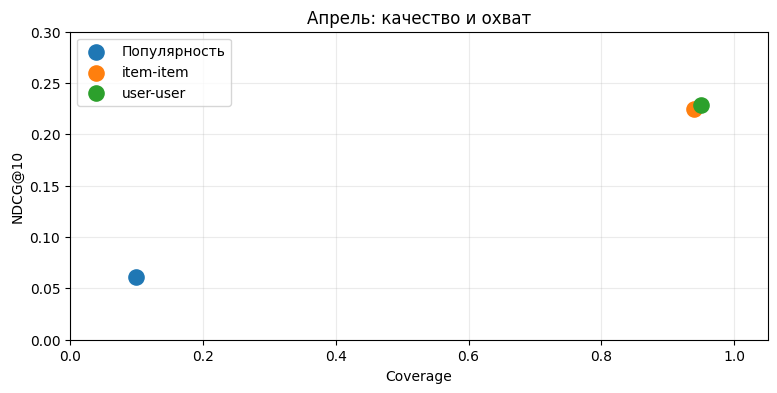

In [23]:
# Шаг М4.03.23 — Качество и охват
fig,ax=plt.subplots()
for name,row in comparison_val.iterrows():
    ax.scatter(row["Coverage"],row["NDCG@K"],s=120,label=name)
ax.set(xlabel="Coverage",ylabel="NDCG@10",title="Апрель: качество и охват",
       xlim=(0,1.05),ylim=(0,max(0.3,comparison_val["NDCG@K"].max()*1.15)))
ax.legend(loc="upper left")
ax.grid(alpha=.25)
plt.show()

## Холодный старт, масштаб и итоговый месяц

Пустой пользовательский профиль не образует соседей; в обеих функциях применяется популярность. Новый товар без событий не имеет поведенческого вектора и требует иного сигнала, например содержания карточки или редакционного правила. Учебные плотные матрицы пар малы. Для большого каталога нужны разреженные взаимодействия, блочный расчёт пересечений и хранение только нескольких сильных соседей.

Числа показывают фактический холодный старт в апрельском срезе. Если есть пустая строка пользователя, обе функции должны дать ей популярный список. Новый товар без событий не получает соседей из B даже тогда, когда его карточка уже находится в каталоге.

In [24]:
# Шаг М4.03.24 — Пустые профили и товары
cold_users=np.flatnonzero(np.asarray(val["B"].sum(axis=1)).ravel()==0)
cold_items=np.flatnonzero(np.asarray(val["B"].sum(axis=0)).ravel()==0)
print("Пользователей без истории:",len(cold_users),"товаров без истории:",len(cold_items))
if len(cold_users):
    x=cold_users[0]
    print("item-item равен популярности:",bool(np.array_equal(best_item_scores[x],pop_scores[x])))
    print("user-user равен популярности:",bool(np.array_equal(best_user_scores[x],pop_scores[x])))
print("Новый товар без событий требует неповеденческого источника ранжирования.")

Пользователей без истории: 20 товаров без истории: 9
item-item равен популярности: True
user-user равен популярности: True
Новый товар без событий требует неповеденческого источника ранжирования.


Одна плотная матрица сходства требует объём, квадратичный числу объектов. Учебные размеры удобны для ручной проверки, но при большом каталоге нужен блочный расчёт и разреженное хранение выбранных top-k связей. Напечатанная оценка не включает временные копии массивов.

In [25]:
# Шаг М4.03.25 — Цена плотной матрицы пар
for objects in (180,300,100_000,1_000_000):
    print(objects,"объектов:",round(objects*objects*8/1024**3,2),"GiB для float64")
print("B хранит",B.nnz,"наблюдённых пар из",B.shape[0]*B.shape[1])

180 объектов: 0.0 GiB для float64
300 объектов: 0.0 GiB для float64
100000 объектов: 74.51 GiB для float64
1000000 объектов: 7450.58 GiB для float64
B хранит 5040 наблюдённых пар из 54000


Апрельские события добавляются в обучающую историю, потому что они известны к майской границе. Майские события в неё не попадают. Печать дат, числа пар и заранее выбранных настроек подтверждает повторную подгонку без нового подбора параметров.

In [26]:
# Шаг М4.03.26 — Повторная подгонка до мая
test=load_context("test")
test_item_scores,_=item_knn_scores(test,**best_item)
test_user_scores,_=user_knn_scores(test,**best_user)
test_pop_scores=popular_scores(test)
print("Граница:",test["cut"].date(),"последнее событие истории:",test["history"].timestamp.max().date())
print("Ненулевых пар до апреля:",val["B"].nnz,"до мая:",test["B"].nnz)
print("Настройки:",best_item,best_user)

Граница: 2025-05-01 последнее событие истории: 2025-04-30
Ненулевых пар до апреля: 5040 до мая: 7650
Настройки: {'neighbors': 20, 'shrink': 0.0} {'neighbors': 20, 'shrink': 5.0}


Итоговая сводка впервые использует майские покупки. Сравнение популярности, item-item и user-user выполняется при одинаковых кандидатах и общей маске виденного. Настройки зафиксированы по апрелю, поэтому майский результат не служит поводом пересматривать их. Значения следует трактовать с учётом синтетической природы событий.

In [27]:
# Шаг М4.03.27 — Майская итоговая оценка
comparison_test=pd.DataFrame({"Популярность":summarize(test_pop_scores,test),
                              "item-item":summarize(test_item_scores,test),
                              "user-user":summarize(test_user_scores,test)}).T
display(comparison_test.round(4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
Популярность,0.0493,0.1233,0.0872,0.4133,0.1167,6.6245,300.0
item-item,0.1090,0.2725,0.2144,0.7333,0.9944,7.4032,300.0
user-user,0.1077,0.2692,0.2148,0.7100,1.0000,7.3902,300.0


Разрез по длине истории показывает, меняется ли качество при разном объёме поведенческого сигнала. Средние значения сопровождаются числом пользователей в группе: малые группы не дают устойчивого вывода. Длина рассчитана по известным товарам до майской границы, а цели по-прежнему представляют только новые покупки мая.

In [28]:
# Шаг М4.03.28 — Майский разрез по длине истории
details=pd.DataFrame({"Популярность":evaluate(test_pop_scores,test).set_index("user_id").ndcg,
                      "item-item":evaluate(test_item_scores,test).set_index("user_id").ndcg,
                      "user-user":evaluate(test_user_scores,test).set_index("user_id").ndcg})
sizes=evaluate(test_pop_scores,test).set_index("user_id").history_size
details["история"]=pd.cut(sizes,bins=[-1,2,8,180],labels=["0–2","3–8","9+"])
display(details.groupby("история",observed=True)[["Популярность","item-item","user-user"]].agg(["mean","count"]).round(4))

Популярность       item-item       user-user      
                mean count      mean count      mean count
история                                                   
0–2           0.0866    10    0.0866    10    0.0866    10
9+            0.0873   290    0.2188   290    0.2192   290

### Как читать результат диагностики

Три вида проверок в этом уроке отвечают на разные вопросы. Ручная сверка косинуса подтверждает формулу и ориентацию осей: товарное произведение должно иметь размер каталога, пользовательское — размер реестра. Сверка суммы вкладов подтверждает механизм конкретной оценки. Временные даты подтверждают, что будущие действия не были включены в построение соседей. Ни одна отдельная проверка не заменяет остальные: правильная арифметика может сопровождаться неверной временной границей, а честный временной срез — ошибкой индексов.

При интерпретации таблиц соседей нужно учитывать происхождение данных. Совпадение двух товаров у нескольких людей показывает совместную встречаемость, но не доказывает, что товар является дополнением к другому. Пользователь с похожей историей может изменить интересы в следующем месяце. Поэтому локальное объяснение сообщает, какие наблюдённые действия повлияли на балл, а не предсказывает достоверное намерение купить. Разница между высоким баллом и фактической будущей покупкой измеряется только на отложенном периоде.

У каждой модели есть свой путь передачи информации. В item-item строка связи начинается у ранее встреченного товара и ведёт к кандидату. В user-user строка связи начинается у целевого пользователя и ведёт к соседним людям; их строки R передают поддержку кандидатам. Это различие помогает проверять размер и направление произведений даже без просмотра исходного кода целиком. Если человек с пустой историей получает персонально выглядящий результат, следует убедиться, что он действительно основан на популярности. Если новый товар без событий оказывается высоко в чисто коллаборативной выдаче, следует проверить наличие другого сигнала или ошибку заполнения нулевых столбцов.

Итоговый майский результат представляет один временной переход на синтетическом журнале. Разрез по длине истории помогает искать ограничения метода, но не превращает малую группу в надёжное доказательство преимущества. Для реального внедрения понадобились бы дополнительные последовательные временные срезы и проверка поведения после показа рекомендаций. В рамках практики достаточно зафиксировать, какую именно задачу измеряет журнал, и не смешивать её с неизвестной реакцией на товары, которые не были показаны.

## Заключение

Итог практики: построены товарные и пользовательские соседи на одном журнале, проверены источники конкретных оценок, параметры выбраны по апрелю, а фиксированные модели повторно обучены до мая и оценены по майским новым покупкам. Общий вывод: поведенческое соседство даёт прозрачный персональный сигнал при достаточной истории; холодный старт и крупный масштаб требуют дополнительных решений.

Дополнительные первичные материалы: [документация cosine_similarity в scikit-learn 1.8](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html) и [работа Hu, Koren и Volinsky о неявной обратной связи](https://yifanhu.net/PUB/cf.pdf).